# Redes convolucionales de segmentación: U-Net en CamVid

Este notebook acompaña la presentación (`index.html`). Hace tres cosas:

1. Carga **CamVid**, un dataset de escenas de calle grabadas desde un auto, donde **cada píxel** tiene una clase.
2. Entrena dos redes pequeñas: un **encoder–decoder sin skip connections** y una **U-Net**.
3. Genera todas las imágenes y números que usa la presentación (`assets/generated/` y `stats.js`).

| Sección | Qué se hace |
|---|---|
| 1 | Configuración |
| 2 | Descargar CamVid |
| 3 | Ver los datos |
| 4 | Preparar los datos |
| 5 | Las dos redes |
| 6 | Entrenamiento |
| 7 | Evaluación (IoU) |
| 8 | Imágenes para la presentación |
| 9 | Paso a paso por dentro de la U-Net |
| 10 | Los 16 filtros y qué se entrena |

Por defecto **no entrena**: usa la U-Net ya entrenada que está en `models/` (`ENTRENAR = False`, ~1 min).
Para entrenar desde cero, pon `ENTRENAR = True` en la sección 1.

**Colab:** *Ejecutar todo*. Con `ENTRENAR = True` conviene *Entorno de ejecución → Cambiar tipo → GPU* (~5 min). Al final se descarga
`presentation_assets.zip`; descomprímelo dentro de `assets/generated/`.
**Local:** córrelo desde la raíz del repositorio; escribe directo en `assets/generated/` (en CPU tarda más).

## 1. Configuración

In [1]:
import sys, subprocess, importlib.util

IN_COLAB = 'google.colab' in sys.modules
for mod, pkg in {'tensorflow': 'tensorflow', 'scipy': 'scipy', 'matplotlib': 'matplotlib'}.items():
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [2]:
import os, json, time, glob, shutil, urllib.request
from types import SimpleNamespace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE = Path('/content') if IN_COLAB else Path('.')
WORK = BASE / ('seg_work' if IN_COLAB else '.work')                       # descargas y modelos (no se suben)
ASSETS = BASE / ('presentation_assets' if IN_COLAB else 'assets/generated')
for p in (WORK, ASSETS):
    p.mkdir(parents=True, exist_ok=True)

H, W = 192, 256        # tamaño de entrada de la red (CamVid viene en 360 x 480; misma proporción 3:4)
EPOCHS = int(os.environ.get('SEG_EPOCHS', 40))
# False = usar la U-Net ya entrenada (carpeta models/ del repositorio, ~1 min).
# True  = entrenar las dos redes desde cero (~5 min con GPU, ~80 min en CPU).
ENTRENAR = False
if os.environ.get('SEG_ENTRENAR') == '1':
    ENTRENAR = True
MODELS = BASE / 'models'
MODELS_URL = 'https://github.com/Mmateo101/Segmentation_presentation/raw/main/models/'
BATCH = 8

STATS = {}             # todos los números que usa la presentación terminan aquí (se exporta a stats.js)
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

I0000 00:00:1793234714.593717    4060 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793234714.655330    4060 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793234716.340891    4060 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: []


Las 11 clases de CamVid y el color con que las vamos a pintar. La clase 11 (*sin etiqueta*) no se usa para entrenar.

In [3]:
CLASSES = ['Cielo', 'Edificio', 'Poste', 'Calle', 'Banqueta', 'Árbol',
           'Señal', 'Barda', 'Auto', 'Peatón', 'Ciclista']
COLORS = ['#7CC6F2', '#8C7AA9', '#FFD23F', '#56657D', '#D9A47A', '#3FA34D',
          '#FF8C42', '#B5651D', '#FF4D6D', '#F15BB5', '#00BBF9']
N_CLASSES = len(CLASSES)
VOID = 11

def hex_to_rgb(h):
    return [int(h[i:i + 2], 16) for i in (1, 3, 5)]

PALETTE = np.array([hex_to_rgb(c) for c in COLORS] + [[0, 0, 0]], dtype=np.uint8)

def colorize(mask, alpha_void=True):
    """Convierte una máscara de clases (H, W) en una imagen RGBA."""
    rgb = PALETTE[mask]
    a = np.where(mask == VOID, 0, 255).astype(np.uint8) if alpha_void else np.full(mask.shape, 255, np.uint8)
    return np.dstack([rgb, a])

STATS['classes'] = [{'name': n, 'color': c} for n, c in zip(CLASSES, COLORS)]

## 2. Descargar CamVid

Usamos la copia de CamVid del repositorio de **SegNet** (Badrinarayanan, Kendall y Cipolla, 2015), que ya viene
separada en *train / val / test* y con las máscaras listas. Solo bajamos la carpeta `CamVid` (~180 MB).

In [4]:
REPO = WORK / 'SegNet-Tutorial'
if not (REPO / 'CamVid' / 'train').exists():
    subprocess.check_call(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse',
                           'https://github.com/alexgkendall/SegNet-Tutorial', str(REPO)])
    subprocess.check_call(['git', '-C', str(REPO), 'sparse-checkout', 'set', 'CamVid'])
CAMVID = REPO / 'CamVid'

def list_split(split):
    images = sorted(glob.glob(str(CAMVID / split / '*.png')))
    masks = [p.replace(f'/{split}/', f'/{split}annot/') for p in images]
    return images, masks

splits = {s: list_split(s) for s in ['train', 'val', 'test']}
for s, (im, _) in splits.items():
    print(f'{s:5s}: {len(im)} imágenes')
STATS['n_images'] = {s: len(v[0]) for s, v in splits.items()}

train: 367 imágenes
val  : 101 imágenes
test : 233 imágenes


## 3. Ver los datos

Cada ejemplo son **dos archivos**: la foto (RGB) y la máscara, una imagen del mismo tamaño donde cada píxel guarda
un número de 0 a 11 (su clase).

foto   : (360, 480, 3) uint8
máscara: (360, 480) uint8 | valores: [ 0  1  2  3  4  5  6  8  9 11]
esquina de la máscara:
 [[1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1]]


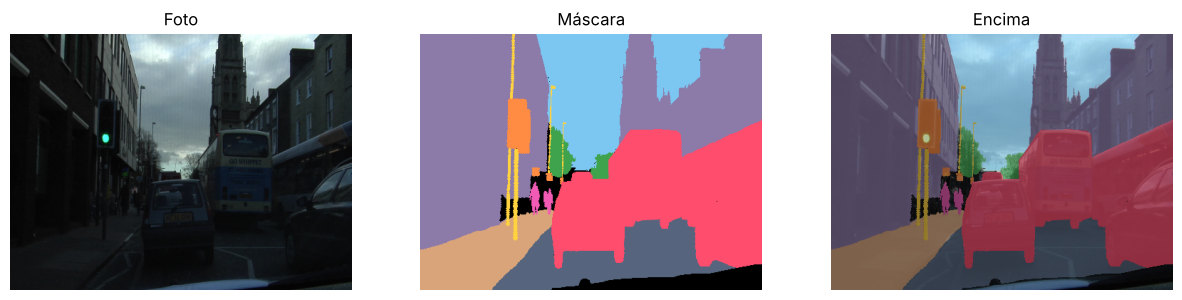

In [5]:
img0 = np.array(Image.open(splits['train'][0][0]))
mask0 = np.array(Image.open(splits['train'][1][0]))
print('foto   :', img0.shape, img0.dtype)
print('máscara:', mask0.shape, mask0.dtype, '| valores:', np.unique(mask0))
print('esquina de la máscara:\n', mask0[:6, :10])
STATS['orig_size'] = [int(img0.shape[0]), int(img0.shape[1])]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(img0); ax[0].set_title('Foto')
ax[1].imshow(colorize(mask0, False)); ax[1].set_title('Máscara')
ax[2].imshow(img0); ax[2].imshow(colorize(mask0), alpha=.55); ax[2].set_title('Encima')
for a in ax: a.axis('off')
plt.show()

¿Qué tan frecuente es cada clase? Contamos píxeles en todo *train*. Las clases chicas (postes, peatones, ciclistas)
casi no aparecen: eso las vuelve difíciles.

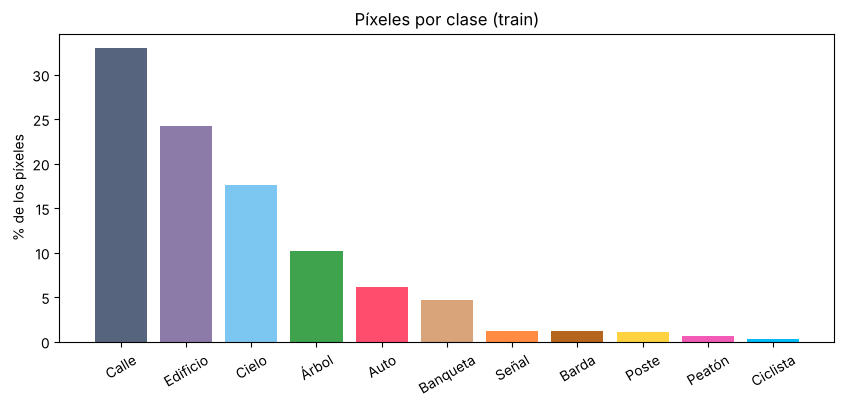

In [6]:
counts = np.zeros(12, dtype=np.int64)
for p in splits['train'][1]:
    counts += np.bincount(np.array(Image.open(p)).ravel(), minlength=12)[:12]
freq = counts[:N_CLASSES] / counts[:N_CLASSES].sum()

order = np.argsort(-freq)
plt.figure(figsize=(10, 4))
plt.bar([CLASSES[i] for i in order], freq[order] * 100, color=[COLORS[i] for i in order])
plt.ylabel('% de los píxeles'); plt.xticks(rotation=30); plt.title('Píxeles por clase (train)')
plt.show()
STATS['pixel_freq'] = [round(float(f), 5) for f in freq]

## 4. Preparar los datos

- Reducimos a **192 × 256** para que entrene rápido.
- Las máscaras se reducen con *nearest* (vecino más cercano) para no inventar clases intermedias.
- **Aumento de datos:** espejo horizontal y cambios de brillo/contraste (las fotos de *test* son más oscuras).
- **Pesos por clase:** como hay muchísima más calle que postes, cada píxel pesa más si su clase es rara
  (*median frequency balancing*, como en SegNet). Los píxeles sin etiqueta pesan 0.

In [7]:
def load_split(split):
    X, Y = [], []
    for ip, mp in zip(*splits[split]):
        X.append(np.array(Image.open(ip).convert('RGB').resize((W, H), Image.BILINEAR)))
        Y.append(np.array(Image.open(mp).resize((W, H), Image.NEAREST)))
    return np.stack(X), np.stack(Y)

X_train, Y_train = load_split('train')
X_val, Y_val = load_split('val')
X_test, Y_test = load_split('test')
print(X_train.shape, Y_train.shape, X_test.shape)

class_weights = np.median(freq) / freq
class_weights = np.append(class_weights, 0.0)      # VOID = 0
print('pesos:', dict(zip(CLASSES, class_weights.round(2))))

def make_dataset(X, Y, training):
    def prep(x, y):
        x = tf.cast(x, tf.float32) / 255.0
        y = tf.cast(y, tf.int32)
        if training:
            if tf.random.uniform(()) > 0.5:                   # espejo horizontal
                x, y = tf.image.flip_left_right(x), tf.reverse(y, axis=[1])
            x = tf.image.random_brightness(x, 0.25)           # más clara o más oscura
            x = tf.image.random_contrast(x, 0.6, 1.4)
            x = tf.clip_by_value(x, 0.0, 1.0)
        w = tf.gather(tf.constant(class_weights, tf.float32), y)
        y = tf.minimum(y, N_CLASSES - 1)                      # VOID se vuelve una clase válida pero con peso 0
        return x, y, w
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.map(prep).batch(BATCH).prefetch(2)

train_ds = make_dataset(X_train, Y_train, True)
val_ds = make_dataset(X_val, Y_val, False)

(367, 192, 256, 3) (367, 192, 256) (233, 192, 256, 3)
pesos: {'Cielo': np.float64(0.27), 'Edificio': np.float64(0.19), 'Poste': np.float64(4.56), 'Calle': np.float64(0.14), 'Banqueta': np.float64(1.0), 'Árbol': np.float64(0.46), 'Señal': np.float64(3.82), 'Barda': np.float64(3.98), 'Auto': np.float64(0.76), 'Peatón': np.float64(7.02), 'Ciclista': np.float64(15.38)}


## 5. Las dos redes

**Encoder:** bloques de dos convoluciones 3×3 + *max pooling*. Cada bloque **reduce la imagen a la mitad** y
**duplica los canales**.

**Decoder:** convolución transpuesta (*upsampling* aprendido) que **duplica el tamaño**, seguida de dos convoluciones.

La única diferencia entre las dos redes: en la **U-Net**, cada bloque del decoder **concatena** el mapa del encoder
del mismo tamaño (*skip connection*). Al final, una convolución 1×1 da **11 números por píxel** y *softmax* los vuelve
probabilidades.

In [8]:
def conv_block(x, filters, name):
    for i in range(2):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False, name=f'{name}_conv{i + 1}')(x)
        x = layers.BatchNormalization(name=f'{name}_bn{i + 1}')(x)
        x = layers.Activation('relu', name=f'{name}_relu{i + 1}')(x)
    return x

def build_model(skips=True, base=16):
    inputs = keras.Input((H, W, 3))
    x = inputs
    encoder = []
    for i, f in enumerate([base, base * 2, base * 4, base * 8]):        # 16, 32, 64, 128
        x = conv_block(x, f, f'enc{i + 1}')
        encoder.append(x)
        x = layers.MaxPooling2D(2, name=f'pool{i + 1}')(x)
    x = conv_block(x, base * 16, 'bottleneck')                         # 256 canales, 12 x 16
    for i, f in reversed(list(enumerate([base, base * 2, base * 4, base * 8]))):
        x = layers.Conv2DTranspose(f, 2, strides=2, name=f'up{i + 1}')(x)
        if skips:
            x = layers.Concatenate(name=f'skip{i + 1}')([x, encoder[i]])
        x = conv_block(x, f, f'dec{i + 1}')
    outputs = layers.Conv2D(N_CLASSES, 1, activation='softmax', name='classes')(x)
    return keras.Model(inputs, outputs, name='unet' if skips else 'encoder_decoder')

unet = build_model(skips=True)
plain = build_model(skips=False)
print(f'U-Net: {unet.count_params():,} parámetros | sin skips: {plain.count_params():,}')

# tamaños de cada nivel, para el diagrama de la presentación
STATS['levels'] = [{'name': n, 'h': int(unet.get_layer(n).output.shape[1]), 'w': int(unet.get_layer(n).output.shape[2]),
                    'c': int(unet.get_layer(n).output.shape[3])}
                   for n in ['enc1_relu2', 'enc2_relu2', 'enc3_relu2', 'enc4_relu2', 'bottleneck_relu2']]
STATS['params'] = {'unet': int(unet.count_params()), 'plain': int(plain.count_params())}
STATS['input'] = [H, W]
print(STATS['levels'])

U-Net: 1,945,691 parámetros | sin skips: 1,749,851
[{'name': 'enc1_relu2', 'h': 192, 'w': 256, 'c': 16}, {'name': 'enc2_relu2', 'h': 96, 'w': 128, 'c': 32}, {'name': 'enc3_relu2', 'h': 48, 'w': 64, 'c': 64}, {'name': 'enc4_relu2', 'h': 24, 'w': 32, 'c': 128}, {'name': 'bottleneck_relu2', 'h': 12, 'w': 16, 'c': 256}]


## 6. Entrenamiento

- **Pérdida:** *cross-entropy* calculada en **cada píxel** y promediada (con los pesos por clase).
- **Métrica:** **IoU** (*intersection over union*) por clase, y su promedio (**mIoU**).

Una pequeña función calcula la IoU con una matriz de confusión. En cada época guardamos la predicción sobre una
misma foto de prueba, para ver cómo "aprende a ver" la red.

- La tasa de aprendizaje baja poco a poco (*cosine decay*), lo que estabiliza el final del entrenamiento.
- Al terminar nos quedamos con los pesos de la época con **mejor mIoU en validación** (no con los de la última).

In [9]:
def confusion(y_true, y_pred):
    keep = y_true != VOID
    idx = y_true[keep].astype(np.int64) * N_CLASSES + y_pred[keep]
    return np.bincount(idx, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)

def iou_from_confusion(cm):
    inter = np.diag(cm)
    union = cm.sum(0) + cm.sum(1) - inter
    return inter / np.maximum(union, 1)

def predict(model, X, batch=16):
    return model.predict(X.astype(np.float32) / 255.0, batch_size=batch, verbose=0)

# La foto que se sigue en toda la presentación: la de test con más clases distintas, autos y peatones.
def score(m):
    present = [c for c in range(N_CLASSES) if (m == c).mean() > 0.002]
    return len(present) + 3 * ((m == 8).mean() > 0.01) + 3 * ((m == 9).mean() > 0.003) + 2 * ((m == 2).mean() > 0.005)
HERO = int(np.argmax([score(m) for m in Y_test]))
print('foto principal:', Path(splits['test'][0][HERO]).name)

class Tracker(keras.callbacks.Callback):
    """Guarda, en cada época, la predicción sobre la foto principal y el mIoU de validación,
    y al final deja en el modelo los pesos de la mejor época."""
    def __init__(self):
        super().__init__()
        self.frames, self.miou = [], []
        self.best, self.best_weights, self.best_epoch = -1, None, 0
    def snap(self):
        self.frames.append(np.argmax(predict(self.model, X_test[HERO:HERO + 1])[0], -1))
    def on_train_begin(self, logs=None):
        self.snap()
    def on_epoch_end(self, epoch, logs=None):
        self.snap()
        cm = confusion(Y_val, np.argmax(predict(self.model, X_val), -1))
        self.miou.append(float(np.nanmean(iou_from_confusion(cm))))
        if self.miou[-1] > self.best:
            self.best, self.best_weights, self.best_epoch = self.miou[-1], self.model.get_weights(), epoch + 1
        print(f'  época {epoch + 1}: val mIoU = {self.miou[-1]:.3f}')
    def on_train_end(self, logs=None):
        self.model.set_weights(self.best_weights)
        print(f'  mejor época: {self.best_epoch} (val mIoU = {self.best:.3f})')

def train(model):
    lr = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=EPOCHS * len(train_ds), alpha=0.05)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy')
    tracker = Tracker()
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[tracker], verbose=2)
    print(f'{model.name}: {(time.time() - t0) / 60:.1f} min')
    MODELS.mkdir(exist_ok=True)                                   # pesos + historial + predicción por época
    model.save(MODELS / f'{model.name}.keras')
    info = {'loss': hist.history['loss'], 'val_loss': hist.history['val_loss'], 'miou': tracker.miou, 'best_epoch': tracker.best_epoch}
    (MODELS / f'{model.name}.json').write_text(json.dumps(info))
    np.savez_compressed(MODELS / f'{model.name}_frames.npz', frames=np.array(tracker.frames, dtype=np.uint8))
    return hist.history, tracker

def load_trained(model):
    """Carga la red ya entrenada (si no está en models/, la descarga del repositorio)."""
    MODELS.mkdir(exist_ok=True)
    for name in [f'{model.name}.keras', f'{model.name}.json', f'{model.name}_frames.npz']:
        if not (MODELS / name).exists():
            print('descargando', name)
            urllib.request.urlretrieve(MODELS_URL + name, MODELS / name)
    model.set_weights(keras.models.load_model(MODELS / f'{model.name}.keras').get_weights())
    info = json.loads((MODELS / f'{model.name}.json').read_text())
    tracker = SimpleNamespace(frames=list(np.load(MODELS / f'{model.name}_frames.npz')['frames']),
                              miou=info['miou'], best_epoch=info['best_epoch'])
    print(f'{model.name}: pesos cargados (mejor época {info["best_epoch"]}, val mIoU {max(info["miou"]):.3f})')
    return {'loss': info['loss'], 'val_loss': info['val_loss']}, tracker

def get_model(model):
    return train(model) if ENTRENAR else load_trained(model)

hist_unet, track_unet = get_model(unet)

foto principal: 0001TP_009930.png


unet: pesos cargados (mejor época 40, val mIoU 0.557)


In [10]:
hist_plain, track_plain = get_model(plain)

encoder_decoder: pesos cargados (mejor época 37, val mIoU 0.453)


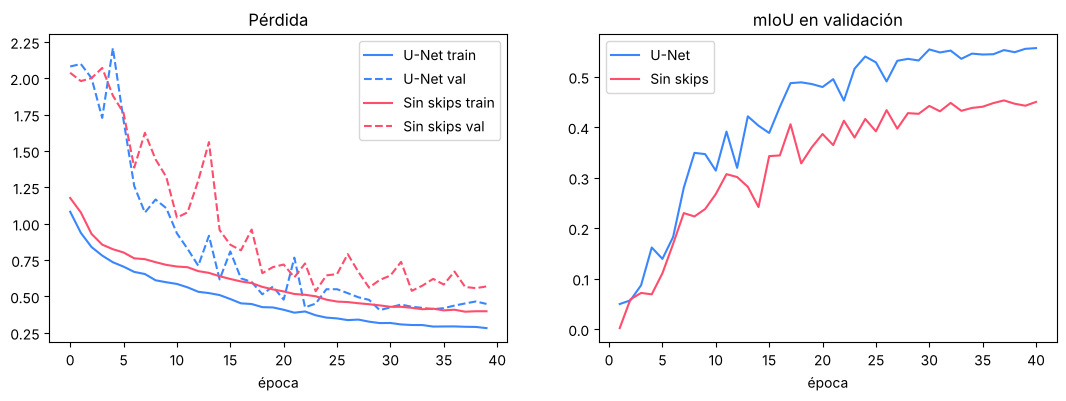

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, t, name, c in [(hist_unet, track_unet, 'U-Net', '#3A86FF'), (hist_plain, track_plain, 'Sin skips', '#FF4D6D')]:
    ax[0].plot(h['loss'], c=c, label=f'{name} train'); ax[0].plot(h['val_loss'], c=c, ls='--', label=f'{name} val')
    ax[1].plot(range(1, len(t.miou) + 1), t.miou, c=c, label=name)
ax[0].set_title('Pérdida'); ax[1].set_title('mIoU en validación'); ax[0].legend(); ax[1].legend()
ax[0].set_xlabel('época'); ax[1].set_xlabel('época')
plt.show()

STATS['history'] = {k: {'loss': [round(v, 4) for v in h['loss']], 'val_loss': [round(v, 4) for v in h['val_loss']],
                        'miou': [round(v, 4) for v in t.miou]}
                    for k, h, t in [('unet', hist_unet, track_unet), ('plain', hist_plain, track_plain)]}
STATS['epochs'] = len(track_unet.miou)
STATS['best_epoch'] = {'unet': track_unet.best_epoch, 'plain': track_plain.best_epoch}

## 7. Evaluación en *test*

clase        U-Net  sin skips
Cielo        0.885      0.836
Edificio     0.430      0.357
Poste        0.125      0.036
Calle        0.853      0.834
Banqueta     0.656      0.592
Árbol        0.620      0.530
Señal        0.098      0.045
Barda        0.138      0.121
Auto         0.557      0.551
Peatón       0.168      0.121
Ciclista     0.168      0.238
mIoU         0.427      0.387
pixel accuracy: U-Net 0.746 | sin skips 0.691


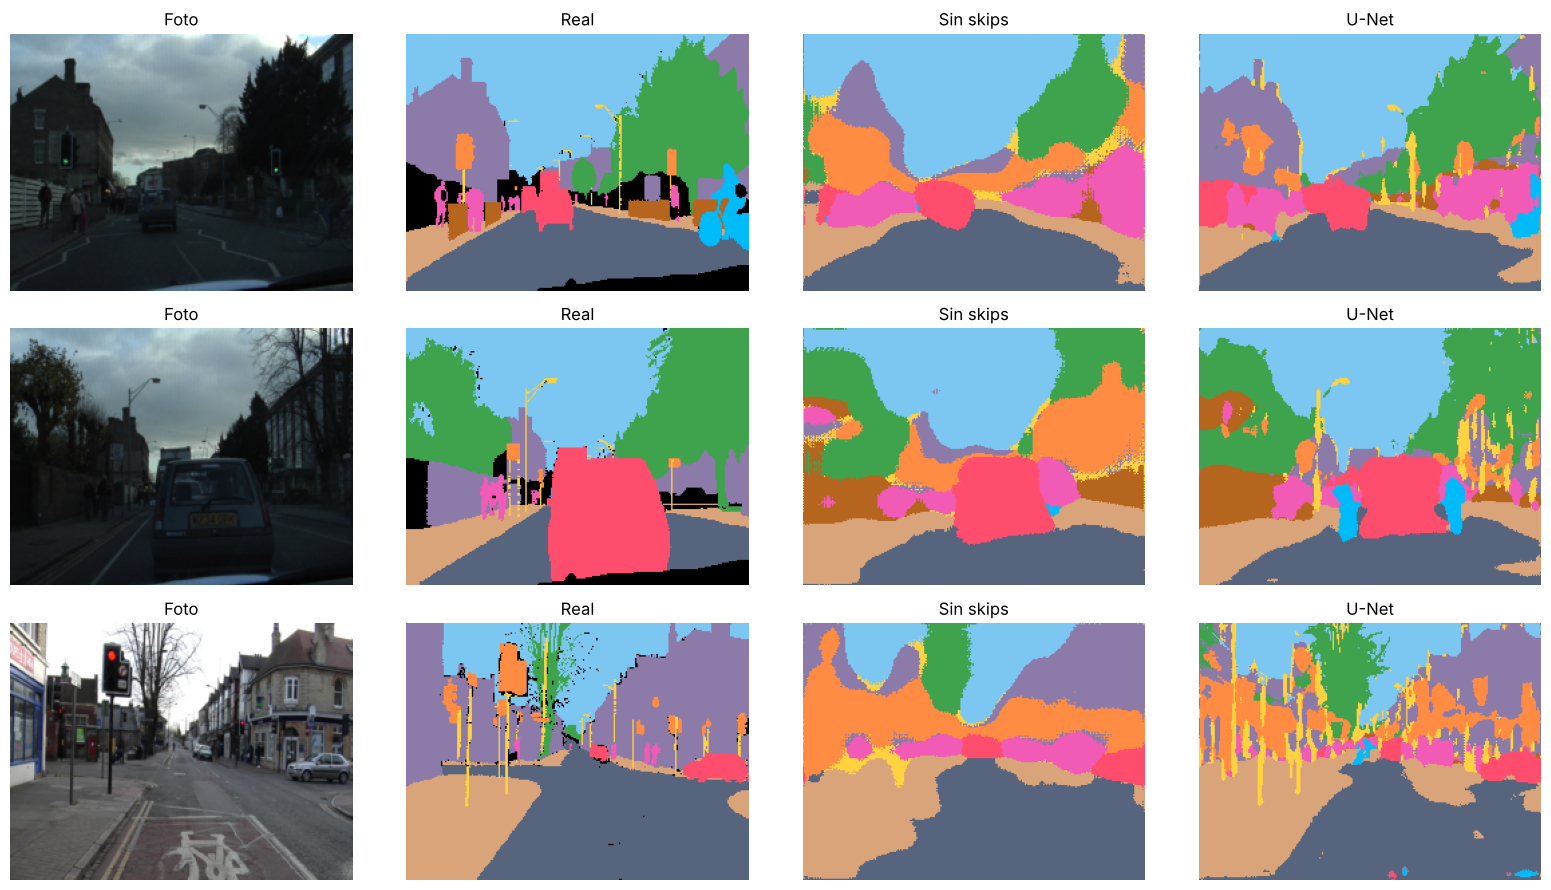

In [12]:
P_unet = predict(unet, X_test)
P_plain = predict(plain, X_test)
pred_unet, pred_plain = P_unet.argmax(-1), P_plain.argmax(-1)

iou_unet = iou_from_confusion(confusion(Y_test, pred_unet))
iou_plain = iou_from_confusion(confusion(Y_test, pred_plain))
pix_acc = lambda p: float((p == Y_test)[Y_test != VOID].mean())

print(f'{"clase":10s} {"U-Net":>7s} {"sin skips":>10s}')
for c in range(N_CLASSES):
    print(f'{CLASSES[c]:10s} {iou_unet[c]:7.3f} {iou_plain[c]:10.3f}')
print(f'{"mIoU":10s} {iou_unet.mean():7.3f} {iou_plain.mean():10.3f}')
print(f'pixel accuracy: U-Net {pix_acc(pred_unet):.3f} | sin skips {pix_acc(pred_plain):.3f}')

STATS['test'] = {'iou_unet': [round(float(v), 4) for v in iou_unet], 'iou_plain': [round(float(v), 4) for v in iou_plain],
                 'miou_unet': round(float(iou_unet.mean()), 4), 'miou_plain': round(float(iou_plain.mean()), 4),
                 'acc_unet': round(pix_acc(pred_unet), 4), 'acc_plain': round(pix_acc(pred_plain), 4)}

fig, ax = plt.subplots(3, 4, figsize=(16, 9))
for r, i in enumerate([HERO, 30, 150]):
    for a, im, t in zip(ax[r], [X_test[i], colorize(Y_test[i], False), colorize(pred_plain[i], False), colorize(pred_unet[i], False)],
                        ['Foto', 'Real', 'Sin skips', 'U-Net']):
        a.imshow(im); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

## 8. Imágenes para la presentación

Todo se guarda en `assets/generated/`. Los nombres de archivo son los que lee `assets/js/deck.js`.

In [13]:
def save_png(arr, name):
    Image.fromarray(arr).save(ASSETS / name, optimize=True)

def save_jpg(arr, name, q=88):
    Image.fromarray(arr).convert('RGB').save(ASSETS / name, quality=q)

hero_path = splits['test'][0][HERO]
hero_full = np.array(Image.open(hero_path).convert('RGB'))                                # 360 x 480
hero_gt_full = np.array(Image.open(splits['test'][1][HERO]))
save_jpg(hero_full, 'hero.jpg', 92)
save_png(colorize(hero_gt_full), 'hero_gt.png')
save_png(colorize(Y_test[HERO]), 'hero_gt_small.png')
save_png(colorize(pred_unet[HERO]), 'hero_unet.png')
save_png(colorize(pred_plain[HERO]), 'hero_plain.png')
STATS['hero'] = Path(hero_path).name

# mapa de error de la U-Net: píxel equivocado = rojo
wrong = (pred_unet[HERO] != Y_test[HERO]) & (Y_test[HERO] != VOID)
err = np.zeros((H, W, 4), np.uint8); err[wrong] = [255, 77, 109, 255]
save_png(err, 'hero_error.png')
STATS['hero_acc'] = round(float(1 - wrong.sum() / (Y_test[HERO] != VOID).sum()), 4)

# cuadrícula de píxeles reales para la portada (24 x 32 celdas) con su clase
gh, gw = 24, 32
small = np.array(Image.fromarray(hero_full).resize((gw, gh), Image.BOX))
cls_grid = np.array(Image.fromarray(hero_gt_full).resize((gw, gh), Image.NEAREST))
STATS['cover_grid'] = {'h': gh, 'w': gw, 'rgb': small.reshape(-1, 3).tolist(), 'cls': cls_grid.ravel().tolist()}

**Clasificación, detección y segmentación** de la misma foto. Las cajas y las instancias salen de las *componentes
conectadas* de la máscara real (cada mancha separada de "Auto" o "Peatón" es un objeto).

In [14]:
boxes, inst = [], np.zeros(hero_gt_full.shape, np.int32)
k = 0
for c in [8, 9, 10]:
    lab, n = ndimage.label(hero_gt_full == c)
    for j, sl in enumerate(ndimage.find_objects(lab)):
        area = (lab[sl] == j + 1).sum()
        if area < 250:
            continue
        k += 1
        inst[lab == j + 1] = k
        y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
        boxes.append({'cls': c, 'x': x0 / hero_gt_full.shape[1], 'y': y0 / hero_gt_full.shape[0],
                      'w': (x1 - x0) / hero_gt_full.shape[1], 'h': (y1 - y0) / hero_gt_full.shape[0]})
STATS['boxes'] = boxes
inst_cols = np.array([[0, 0, 0, 0]] + [hex_to_rgb(c) + [255] for c in
                     ['#FF4D6D', '#FFD23F', '#00BBF9', '#3FA34D', '#F15BB5', '#FF8C42', '#8C7AA9', '#7CC6F2',
                      '#D9A47A', '#B5651D', '#56657D', '#FFFFFF'] * 4], np.uint8)
save_png(inst_cols[np.minimum(inst, len(inst_cols) - 1)], 'hero_instances.png')
things = np.isin(hero_gt_full, [8, 9, 10])
sem = np.zeros((*hero_gt_full.shape, 4), np.uint8); sem[things] = colorize(hero_gt_full)[things]
save_png(sem, 'hero_things.png')
print(len(boxes), 'objetos')

6 objetos


**Lo que pierde una CNN de clasificación.** Si la red solo pudiera responder a la resolución del cuello de botella
(12 × 16), lo mejor posible sería la máscara real reducida a ese tamaño y estirada de vuelta.

In [15]:
lv = STATS['levels'][-1]
coarse = np.array(Image.fromarray(Y_test[HERO]).resize((lv['w'], lv['h']), Image.NEAREST))
save_png(colorize(coarse), 'hero_coarse.png')                                     # el navegador la estira

**Mapas de características** de la U-Net entrenada en cada nivel del encoder (el canal más activo de cada uno).

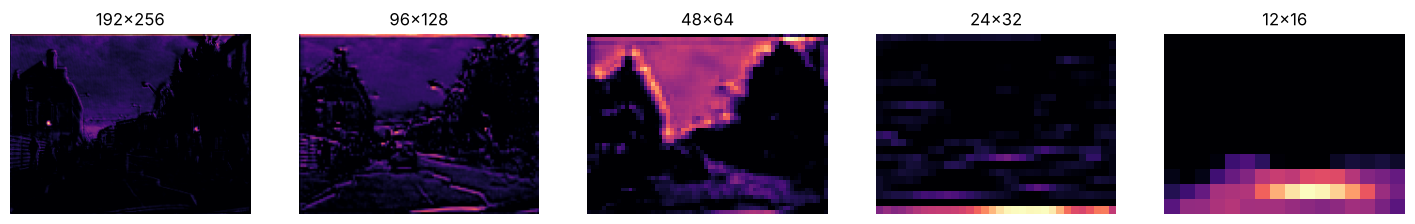

In [16]:
fm_model = keras.Model(unet.input, [unet.get_layer(l['name']).output for l in STATS['levels']])
fmaps = fm_model.predict(X_test[HERO:HERO + 1].astype(np.float32) / 255.0, verbose=0)
cmap = plt.get_cmap('magma')
STATS['fmaps'] = []
for i, f in enumerate(fmaps):
    f = f[0]
    best = np.argsort(-f.reshape(-1, f.shape[-1]).std(0))[:4]               # los 4 canales con más contraste
    for j, ch in enumerate(best):
        a = f[..., ch]; a = (a - a.min()) / (a.max() - a.min() + 1e-6)
        save_png((cmap(a)[..., :3] * 255).astype(np.uint8), f'fmap_{i}_{j}.png')
    STATS['fmaps'].append({'h': f.shape[0], 'w': f.shape[1], 'c': f.shape[2]})

fig, ax = plt.subplots(1, 5, figsize=(18, 3))
for i in range(5):
    ax[i].imshow(Image.open(ASSETS / f'fmap_{i}_0.png')); ax[i].set_title(f"{STATS['fmaps'][i]['h']}×{STATS['fmaps'][i]['w']}"); ax[i].axis('off')
plt.show()

**Softmax por píxel.** Para la presentación guardamos, en una cuadrícula de 24 × 32 celdas, las 3 clases más
probables de cada celda según la U-Net.

In [17]:
probs = P_unet[HERO]                                                         # 192 x 256 x 11
ph, pw = H // 24, W // 32
cells = probs.reshape(24, ph, 32, pw, N_CLASSES).mean((1, 3))
top = []
for p in cells.reshape(-1, N_CLASSES):
    idx = np.argsort(-p)[:3]
    top.append([[int(c), round(float(p[c]), 3)] for c in idx])
STATS['probs'] = {'h': 24, 'w': 32, 'top': top}

**Cómo aprende:** la predicción sobre la foto principal después de cada época, en un solo *sprite* vertical.

In [18]:
def sprite(frames, name, every=1):
    sel = frames[::every]
    if (len(frames) - 1) % every:
        sel.append(frames[-1])
    big = np.concatenate([colorize(f, False)[..., :3] for f in sel], axis=0)
    save_jpg(big, name, 85)
    return len(sel)

STATS['sprite_unet'] = {'file': 'epochs_unet.jpg', 'frames': sprite(track_unet.frames, 'epochs_unet.jpg')}
STATS['sprite_plain'] = {'file': 'epochs_plain.jpg', 'frames': sprite(track_plain.frames, 'epochs_plain.jpg')}

**Más ejemplos de test** (para la escena de resultados): las 3 fotos donde la U-Net acierta más y la peor.

In [19]:
per_img = [float((pred_unet[i] == Y_test[i])[Y_test[i] != VOID].mean()) for i in range(len(X_test))]
rank = np.argsort(per_img)
picks = {'good': [int(i) for i in rank[::-1] if i != HERO][:3], 'bad': [int(rank[0])]}
STATS['examples'] = []
for kind, ids in picks.items():
    for i in ids:
        tag = f'{kind}_{i}'
        save_jpg(X_test[i], f'ex_{tag}.jpg')
        save_png(colorize(Y_test[i]), f'ex_{tag}_gt.png')
        save_png(colorize(pred_unet[i]), f'ex_{tag}_unet.png')
        save_png(colorize(pred_plain[i]), f'ex_{tag}_plain.png')
        STATS['examples'].append({'tag': tag, 'kind': kind, 'acc': round(per_img[i], 4)})
print(STATS['examples'])

[{'tag': 'good_67', 'kind': 'good', 'acc': 0.862}, {'tag': 'good_111', 'kind': 'good', 'acc': 0.8426}, {'tag': 'good_198', 'kind': 'good', 'acc': 0.8412}, {'tag': 'bad_149', 'kind': 'bad', 'acc': 0.4551}]


## 9. Paso a paso por dentro de la U-Net

Pasamos la foto principal por la U-Net entrenada y guardamos lo que sale de **cada operación**: la primera
convolución, BatchNorm + ReLU, max pooling, la convolución transpuesta, la concatenación y el softmax final.
Así la presentación puede explicar cada paso con los números reales de la red.

In [20]:
STEP_LAYERS = ['enc1_conv1', 'enc1_bn1', 'enc1_relu1', 'enc1_relu2', 'pool1', 'bottleneck_relu2',
               'up4', 'enc4_relu2', 'dec4_relu2', 'up1', 'dec1_relu2', 'classes']
probe = keras.Model(unet.input, [unet.get_layer(n).output for n in STEP_LAYERS])
xh = X_test[HERO:HERO + 1].astype(np.float32) / 255.0
T = {n: o[0] for n, o in zip(STEP_LAYERS, probe.predict(xh, verbose=0))}
for n, t in T.items():
    print(f'{n:18s} {t.shape}')

def r2(a):
    return np.round(np.asarray(a, dtype=float), 2).tolist()

def most_active(t):
    """Canal con más contraste (desviación estándar más alta)."""
    return int(np.argmax(t.reshape(-1, t.shape[-1]).std(0)))

def to_magma(a):
    a = (a - a.min()) / (a.max() - a.min() + 1e-6)
    return (cmap(a)[..., :3] * 255).astype(np.uint8)

def to_diverging(a):
    """Negativos en azul, positivos en coral, cero en negro."""
    m = np.abs(a).max() + 1e-6
    neg, pos = np.clip(-a / m, 0, 1), np.clip(a / m, 0, 1)
    blue, coral = np.array([58, 134, 255]), np.array([255, 77, 109])
    return (neg[..., None] * blue + pos[..., None] * coral).astype(np.uint8)

# Paso 0: la entrada son 3 canales (R, G, B)
for k, ch in enumerate('rgb'):
    tint = np.zeros((H, W, 3), np.uint8); tint[..., k] = X_test[HERO][..., k]
    save_png(tint, f'step_in_{ch}.png')

# Paso 1: convolución 3x3. Guardamos un filtro real (3 x 3 x 3 pesos) y un parche de 5 x 5 píxeles.
c1 = most_active(T['enc1_relu1'])
kernel = unet.get_layer('enc1_conv1').get_weights()[0][..., c1]                 # 3 x 3 x 3
edge = np.argwhere(np.isin(Y_test[HERO], [8]))                                 # un punto sobre el auto
r0, q0 = (edge[len(edge) // 2] if len(edge) else (H // 2, W // 2))
r0, q0 = int(np.clip(r0, 3, H - 4)), int(np.clip(q0, 3, W - 4))
patch = X_test[HERO][r0 - 2:r0 + 3, q0 - 2:q0 + 3]                            # 5 x 5 x 3
out3 = T['enc1_conv1'][r0 - 1:r0 + 2, q0 - 1:q0 + 2, c1]                      # 3 x 3 resultados reales
check = float((patch[0:3, 0:3] / 255.0 * kernel).sum())
print(f'conv en la esquina: a mano {check:.3f} | red {out3[0, 0]:.3f}')
STATS['conv_demo'] = {'pos': [r0, q0], 'channel': c1, 'patch': patch.astype(int).tolist(),
                      'kernel': r2(kernel), 'out': r2(out3)}
save_png(to_diverging(T['enc1_conv1'][..., c1]), 'step_conv.png')
# Paso 2: BatchNorm y ReLU sobre ese mismo canal
save_png(to_diverging(T['enc1_bn1'][..., c1]), 'step_bn.png')
save_png(to_magma(T['enc1_relu1'][..., c1]), 'step_relu.png')
STATS['relu_zero'] = round(float((T['enc1_relu1'][..., c1] == 0).mean()), 3)

# Paso 3: la segunda convolución deja 16 mapas de 192 x 256 (mosaico de 4 x 4)
f16 = T['enc1_relu2']
tiles = [np.array(Image.fromarray(to_magma(f16[..., k])).resize((128, 96))) for k in range(16)]
save_png(np.concatenate([np.concatenate(tiles[r * 4:(r + 1) * 4], 1) for r in range(4)], 0), 'step_16maps.png')

# Paso 4: max pooling 2x2 en un parche de 8 x 8 del canal más activo
c2 = most_active(f16)
a2 = f16[..., c2]
# la ventana de 8 x 8 (en posiciones pares) con más contraste
best_std, pr, pq = -1, 0, 0
for i in range(0, H - 8, 2):
    for j in range(0, W - 8, 2):
        sd = a2[i:i + 8, j:j + 8].std()
        if sd > best_std:
            best_std, pr, pq = sd, i, j
p8 = a2[pr:pr + 8, pq:pq + 8]
STATS['pool_demo'] = {'pos': [pr, pq], 'channel': c2, 'patch': r2(p8),
                      'out': r2(p8.reshape(4, 2, 4, 2).max((1, 3)))}
save_png(to_magma(a2), 'step_prepool.png')
save_png(to_magma(T['pool1'][..., c2]), 'step_pool.png')

# Pasos del decoder: conv transpuesta, concatenación (skip) y convoluciones
for lv, up, enc, dec in [(4, 'up4', 'enc4_relu2', 'dec4_relu2'), (1, 'up1', 'enc1_relu2', 'dec1_relu2')]:
    save_png(to_magma(T[up][..., most_active(T[up])]), f'step_up{lv}.png')
    save_png(to_magma(T[enc][..., most_active(T[enc])]), f'step_skip{lv}.png')
    save_png(to_magma(T[dec][..., most_active(T[dec])]), f'step_dec{lv}.png')
save_png(to_magma(T['bottleneck_relu2'][..., most_active(T['bottleneck_relu2'])]), 'step_bottleneck.png')

# Último paso: conv 1x1 + softmax = una probabilidad por clase en cada píxel
STATS['prob_maps'] = []
for c in [8, 3, 0, 9, 5]:
    p = T['classes'][..., c]
    rgba = np.zeros((H, W, 4), np.uint8); rgba[..., :3] = PALETTE[c]; rgba[..., 3] = (p * 255).astype(np.uint8)
    save_png(rgba, f'step_prob_{c}.png')
    STATS['prob_maps'].append({'cls': c, 'max': round(float(p.max()), 3)})

# La red completa, capa por capa (para el mapa de la arquitectura)
STATS['layer_shapes'] = [{'name': l.name, 'shape': [int(d) for d in l.output.shape[1:]]}
                         for l in unet.layers if any(l.name.endswith(s) for s in ('relu2', 'pool1', 'pool2', 'pool3', 'pool4'))
                         or l.name.startswith(('up', 'skip')) or l.name == 'classes']
print(STATS['layer_shapes'])

enc1_conv1         (192, 256, 16)
enc1_bn1           (192, 256, 16)
enc1_relu1         (192, 256, 16)
enc1_relu2         (192, 256, 16)
pool1              (96, 128, 16)
bottleneck_relu2   (12, 16, 256)
up4                (24, 32, 128)
enc4_relu2         (24, 32, 128)
dec4_relu2         (24, 32, 128)
up1                (192, 256, 16)
dec1_relu2         (192, 256, 16)
classes            (192, 256, 11)


conv en la esquina: a mano 0.042 | red 0.042


[{'name': 'enc1_relu2', 'shape': [192, 256, 16]}, {'name': 'pool1', 'shape': [96, 128, 16]}, {'name': 'enc2_relu2', 'shape': [96, 128, 32]}, {'name': 'pool2', 'shape': [48, 64, 32]}, {'name': 'enc3_relu2', 'shape': [48, 64, 64]}, {'name': 'pool3', 'shape': [24, 32, 64]}, {'name': 'enc4_relu2', 'shape': [24, 32, 128]}, {'name': 'pool4', 'shape': [12, 16, 128]}, {'name': 'bottleneck_relu2', 'shape': [12, 16, 256]}, {'name': 'up4', 'shape': [24, 32, 128]}, {'name': 'skip4', 'shape': [24, 32, 256]}, {'name': 'dec4_relu2', 'shape': [24, 32, 128]}, {'name': 'up3', 'shape': [48, 64, 64]}, {'name': 'skip3', 'shape': [48, 64, 128]}, {'name': 'dec3_relu2', 'shape': [48, 64, 64]}, {'name': 'up2', 'shape': [96, 128, 32]}, {'name': 'skip2', 'shape': [96, 128, 64]}, {'name': 'dec2_relu2', 'shape': [96, 128, 32]}, {'name': 'up1', 'shape': [192, 256, 16]}, {'name': 'skip1', 'shape': [192, 256, 32]}, {'name': 'dec1_relu2', 'shape': [192, 256, 16]}, {'name': 'classes', 'shape': [192, 256, 11]}]


## 10. Los 16 filtros y qué se entrena

- La primera convolución tiene **16 filtros** de 3 × 3 × 3. Cada filtro produce un mapa; por eso la salida es
  192 × 256 × **16**. Guardamos los 16 filtros (como imágenes de 3 × 3 píxeles) y sus 16 mapas.
- Contamos qué pesos **se entrenan** (los cambia el optimizador) y cuáles **no** (BatchNorm guarda una media y
  una varianza que se calculan, no se aprenden). Max pooling, ReLU, concatenar y softmax no tienen pesos.

In [21]:
first = keras.Model(unet.input, unet.get_layer('enc1_conv1').output)
c1_maps = first.predict(X_test[HERO:HERO + 1].astype(np.float32) / 255.0, verbose=0)[0]       # 192 x 256 x 16
k1 = unet.get_layer('enc1_conv1').get_weights()[0]                                               # 3 x 3 x 3 x 16

def diverging(a):
    m = np.abs(a).max() + 1e-6
    neg, pos = np.clip(-a / m, 0, 1), np.clip(a / m, 0, 1)
    return (neg[..., None] * np.array([58, 134, 255]) + pos[..., None] * np.array([255, 77, 109])).astype(np.uint8)

tiles = [np.array(Image.fromarray(diverging(c1_maps[..., k])).resize((128, 96))) for k in range(16)]
Image.fromarray(np.concatenate([np.concatenate(tiles[r * 4:(r + 1) * 4], 1) for r in range(4)], 0)).save(ASSETS / 'step_conv16.png')
kern_rgb = []
for k in range(16):
    w = k1[..., k]
    w = (w - w.min()) / (w.max() - w.min() + 1e-6)                 # cada filtro visto como una mini imagen RGB
    kern_rgb.append((w * 255).astype(int).tolist())
STATS['conv1_kernels'] = kern_rgb

groups = {}
for layer in unet.layers:
    kind = type(layer).__name__
    if kind == 'Conv2D':
        kind = 'conv1x1' if layer.kernel_size == (1, 1) else 'conv3x3'
    for w in layer.weights:
        part = w.name.split('/')[-1].split(':')[0]
        key = f"{kind}.{part}.{'train' if w.trainable else 'fixed'}"
        groups[key] = groups.get(key, 0) + int(np.prod(w.shape))
for k, v in groups.items():
    print(f'{k:40s} {v:>10,}')
STATS['params_detail'] = groups
print('total:', sum(groups.values()), '=', unet.count_params())

conv3x3.kernel.train                      1,765,296
BatchNormalization.gamma.train                1,472
BatchNormalization.beta.train                 1,472
BatchNormalization.moving_mean.fixed          1,472
BatchNormalization.moving_variance.fixed      1,472
Conv2DTranspose.kernel.train                174,080
Conv2DTranspose.bias.train                      240
conv1x1.kernel.train                            176
conv1x1.bias.train                               11
total: 1945691 = 1945691


### Exportar `stats.js`

In [22]:
(ASSETS / 'stats.js').write_text('/* generado por Segmentation_UNet.ipynb */\nwindow.SEG = ' +
                                 json.dumps(STATS, ensure_ascii=False, separators=(',', ':')) + ';\n', encoding='utf-8')
print('archivos en', ASSETS.resolve(), ':', len(list(ASSETS.iterdir())))

if IN_COLAB:
    shutil.make_archive('/content/presentation_assets', 'zip', ASSETS)
    from google.colab import files
    files.download('/content/presentation_assets.zip')

archivos en /home/claude/segmentation_presentation/assets/generated : 102
